# 06 · Shared seasonality can look like a health signal

[Run this notebook in your browser ↗](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=06_environment_and_health.ipynb)

**Evidence: a real NOAA SST analysis series, followed by a separate synthetic environmental/effort experiment.** First inspect the observed temperature context and its provider uncertainty; then explore why correlations can arise without a causal relationship. No disease cases or observed chlorophyll data are included.

Data: [NOAA NCEI OISST v2.1, final](https://coastwatch.pfeg.noaa.gov/erddap/griddap/ncdcOisst21Agg_LonPM180.html), distributed by NOAA CoastWatch ERDDAP; free use and redistribution under the provider's recorded terms. Scientific context: [CDC on warming coastal waters and Vibrio](https://www.cdc.gov/han/2023/han00497.html); [NASA ocean-color context](https://www.earthdata.nasa.gov/s3fs-public/2024-07/SNWG%20Water%20Quality%20Fact%20Sheet.pdf). Temperature and chlorophyll are contextual indicators, not diagnoses of pathogens or toxins.

Run the setup cell first. Browser Python downloads numerical packages on first use. Core exercises use bundled files; live access is optional. Export your notebook to preserve work.

In [1]:
import sys
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["numpy", "pandas", "matplotlib", "scipy", "plotly"])
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import oceanlab as lab
from IPython.display import display
print("Runtime:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)

Runtime: 3.13.14 | NumPy: 2.3.3 | pandas: 2.3.2


## Observed environmental context
This 2024 daily series is one 0.25° cell at 54.625°N, 12.125°E in the Baltic, north of Rostock. OISST blends satellite and in situ measurements into a spatially complete analysis; it is not a direct cloud-free observation every day. Shading shows the provider-estimated **±1 standard deviation**, not a confidence interval or the full uncertainty of local conditions. The year differs from the 2017–2021 vessel study, so these layers are not used to infer a contemporaneous fishing-health association.

,time,zlev,latitude,longitude,sst,err
0,2024-01-01 12:00:00+00:00,0.0,54.625,12.125,4.70,0.17
1,2024-01-02 12:00:00+00:00,0.0,54.625,12.125,4.77,0.21
2,2024-01-03 12:00:00+00:00,0.0,54.625,12.125,4.85,0.29
3,2024-01-04 12:00:00+00:00,0.0,54.625,12.125,4.66,0.22
4,2024-01-05 12:00:00+00:00,0.0,54.625,12.125,4.62,0.18


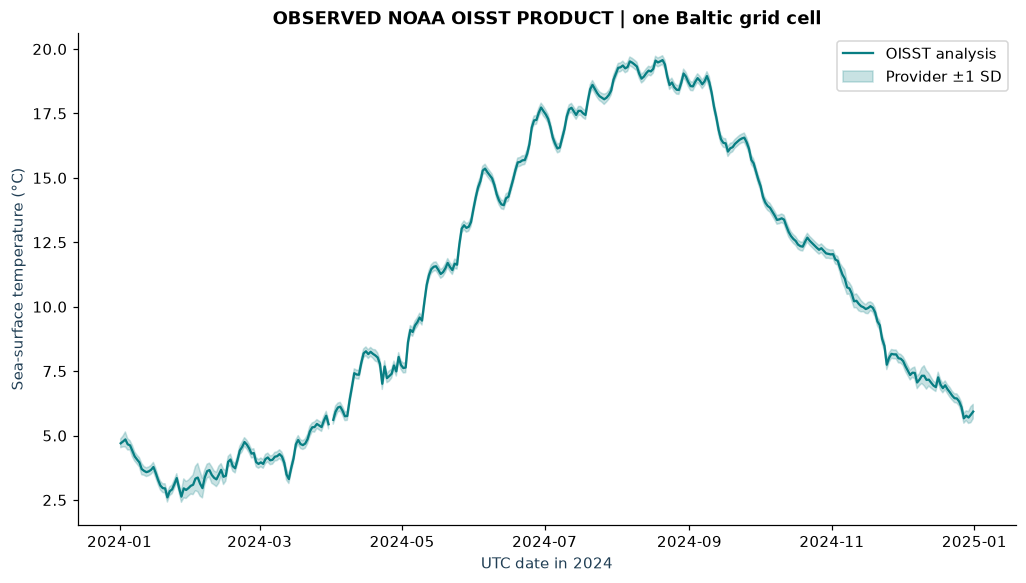

NOAA National Centers for Environmental Information; distributed by NOAA CoastWatch ERDDAP
Missing archive dates (not imputed): ['2024-03-31T12:00:00+00:00']


In [2]:
sst=pd.read_csv(lab.DATA/"noaa_oisst_2024_point.csv",parse_dates=["time"])
record=json.loads((lab.DATA/"noaa_oisst.provenance.json").read_text())
display(sst.head())
fig,ax=plt.subplots()
daily=sst.set_index("time").reindex(pd.date_range(sst.time.min(),sst.time.max(),freq="D"))
ax.plot(daily.index,daily.sst,color="#087e83",label="OISST analysis")
ax.fill_between(daily.index,daily.sst-daily.err,daily.sst+daily.err,color="#087e83",alpha=.22,label="Provider ±1 SD")
ax.set(xlabel="UTC date in 2024",ylabel="Sea-surface temperature (°C)",title="OBSERVED NOAA OISST PRODUCT | one Baltic grid cell")
ax.legend();plt.show()
print(record["attribution"])
print("Missing archive dates (not imputed):",record["missing_dates_utc"])

## Now switch to a synthetic experiment
The following 120 months are invented, including SST, chlorophyll and effort. They are not derived from the NOAA series. A shared seasonal cycle and trend create a correlation even though the simulation contains no causal effect of effort on temperature or disease.

,month,sst_c,chlorophyll_mg_m3,effort_hours
0,0,16.182830,0.632432,72.985114
1,1,18.396010,0.989496,89.545900
2,2,21.686423,1.281972,83.858681
3,3,22.624339,2.114929,89.163638
4,4,20.105531,2.263104,115.554485


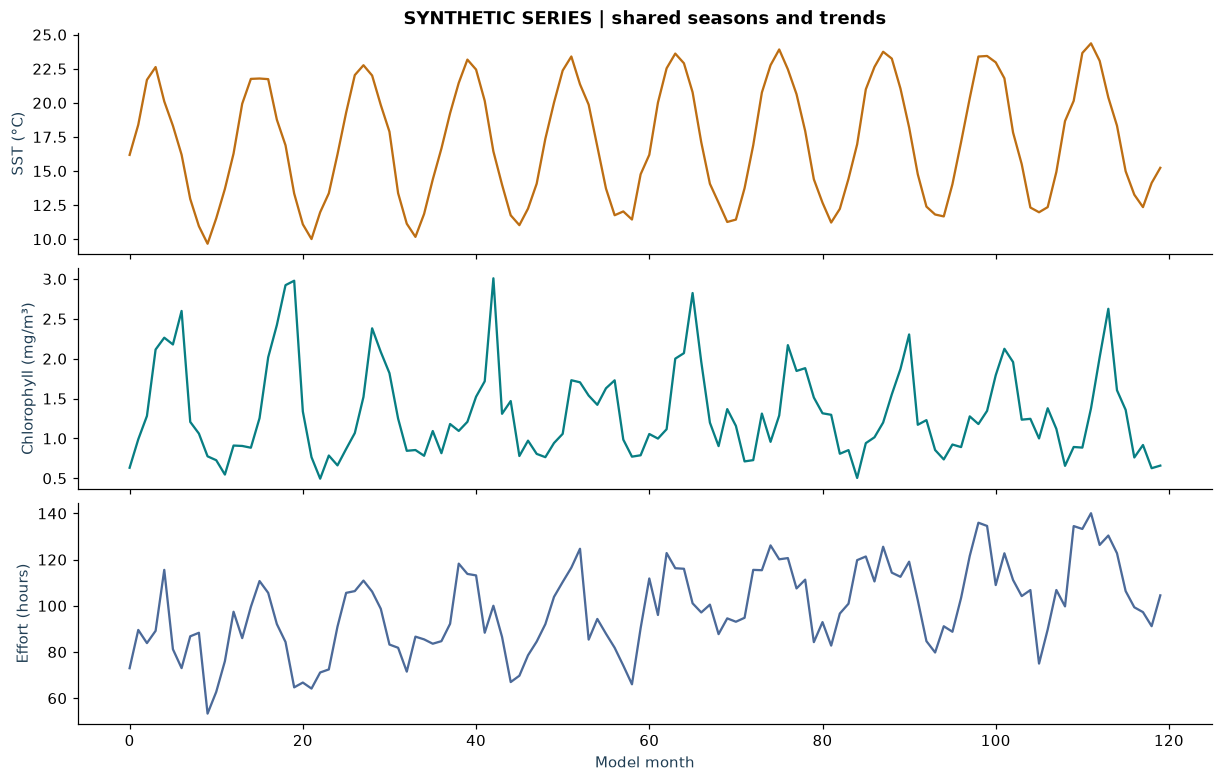

In [3]:
env=lab.environment()
display(env.head())
fig,axes=plt.subplots(3,1,sharex=True,figsize=(11,7),constrained_layout=True)
for ax,col,label,color in zip(axes,["sst_c","chlorophyll_mg_m3","effort_hours"],
    ["SST (°C)","Chlorophyll (mg/m³)","Effort (hours)"],["#bd6e13","#087e83","#4c6a99"]):
    ax.plot(env.month,env[col],color=color);ax.set_ylabel(label)
axes[0].set_title("SYNTHETIC SERIES | shared seasons and trends")
axes[-1].set_xlabel("Model month");plt.show()

## Change the comparison
Both effort and temperature were constructed with a seasonal cycle and time trend. Regress each on a constant, linear time, and annual sine/cosine terms, then compare the residuals. This is a confounding demonstration, not a recommended epidemiological model or a proof that all confounding has been removed.

raw_correlation                            0.754619
after_removing_constructed_shared_terms   -0.185372
dtype: float64

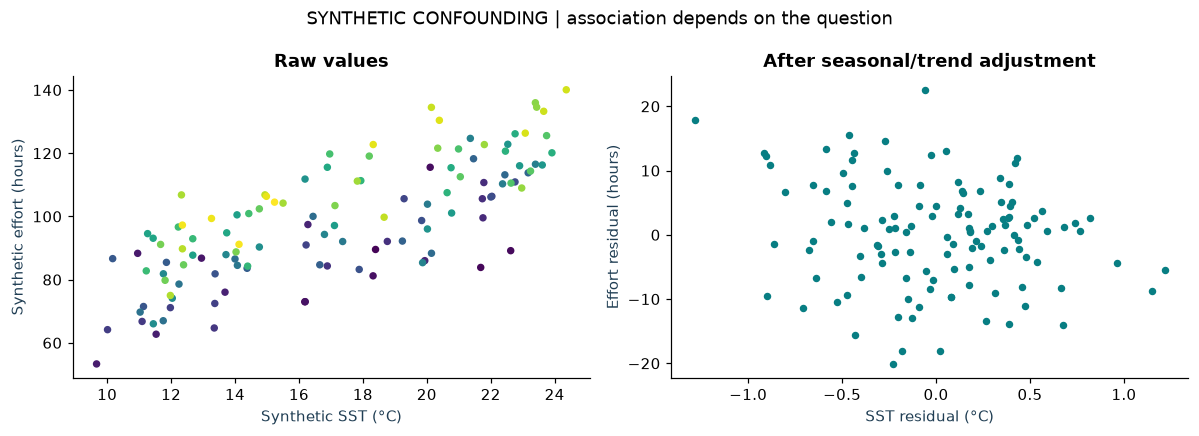

In [4]:
t=env.month.to_numpy()
X=np.column_stack([np.ones(len(t)),t,np.sin(2*np.pi*t/12),np.cos(2*np.pi*t/12)])
residuals={}
for key in ["sst_c","effort_hours"]:
    coefficients=np.linalg.lstsq(X,env[key],rcond=None)[0]
    residuals[key]=env[key]-X@coefficients
raw=env[["sst_c","effort_hours"]].corr().iloc[0,1]
adjusted=pd.DataFrame(residuals).corr().iloc[0,1]
display(pd.Series({"raw_correlation":raw,"after_removing_constructed_shared_terms":adjusted}))
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(env.sst_c,env.effort_hours,s=15,c=t,cmap="viridis")
axes[0].set(xlabel="Synthetic SST (°C)",ylabel="Synthetic effort (hours)",title="Raw values")
axes[1].scatter(residuals["sst_c"],residuals["effort_hours"],s=15,color="#087e83")
axes[1].set(xlabel="SST residual (°C)",ylabel="Effort residual (hours)",title="After seasonal/trend adjustment")
fig.suptitle("SYNTHETIC CONFOUNDING | association depends on the question");plt.tight_layout();plt.show()

## Design a real One Health extension
A Vibrio study would need environmental measurements, appropriate salinity and exposure information, case definitions, population denominators, care-seeking and reporting context, and ethical governance. A harmful-algal-bloom study needs species or toxin evidence. A mercury study needs contaminant sampling and consumption information. An offshore activity map supplies none of those outcomes by itself.

**Try it:** remove the trend term from `X`. Then remove the seasonal terms. Explain how each choice changes the residual association. Identify a time lag you would justify biologically before looking at an outcome.